<a id="4"></a>
# <p style="background-color:#001f3f;font-family:newtimeroman;color:#FFF9ED;font-size:150%;text-align:center;border-radius:10px 10px;">Importing Libraries</p>

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


<a id="4"></a>
# <p style="background-color:#001f3f;font-family:newtimeroman;color:#FFF9ED;font-size:150%;text-align:center;border-radius:10px 10px;">Loading Data</p>

<!-- Team roles and completion status appear beside the relevant notebook sections. -->

In [2]:
# Legacy Kaggle-only loader (kept for reference).
# It is intentionally commented out; use the portable loader in the next cell.
# df_circuits = pd.read_csv('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/circuits.csv')
# df_constructor_results = pd.read_csv('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_results.csv')
# df_constructor_standings = pd.read_csv('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_standings.csv')
# df_constructors = pd.read_csv('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructors.csv')
# df_driver_standings = pd.read_csv('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/driver_standings.csv')
# df_drivers = pd.read_csv('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/drivers.csv')
# df_lap_times = pd.read_csv('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/lap_times.csv')
# df_pit_stops = pd.read_csv('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/pit_stops.csv')
# df_qualifying = pd.read_csv('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/qualifying.csv')
# df_races = pd.read_csv('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/races.csv')
# df_results = pd.read_csv('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/results.csv')
# df_seasons = pd.read_csv('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/seasons.csv')
# df_sprint_results = pd.read_csv('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/sprint_results.csv')
# df_status = pd.read_csv('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/status.csv')

In [3]:
from pathlib import Path

# Works locally with data/raw/ and on Kaggle after the F1 dataset is added as an input.
DATA_DIR_CANDIDATES = [
    Path('/kaggle/input/formula-1-world-championship-1950-2020'),
    Path('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020'),
    Path.cwd() / 'data' / 'raw',
    Path.cwd().parent / 'data' / 'raw',
]

DATA_DIR = next((path for path in DATA_DIR_CANDIDATES if (path / 'results.csv').is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        'Formula 1 CSV files not found. Extract the dataset into data/raw locally, '
        'or add the Formula 1 World Championship dataset as a Kaggle input.'
    )

DATA_FILES = {
    'circuits': 'circuits.csv',
    'constructor_results': 'constructor_results.csv',
    'constructor_standings': 'constructor_standings.csv',
    'constructors': 'constructors.csv',
    'driver_standings': 'driver_standings.csv',
    'drivers': 'drivers.csv',
    'lap_times': 'lap_times.csv',
    'pit_stops': 'pit_stops.csv',
    'qualifying': 'qualifying.csv',
    'races': 'races.csv',
    'results': 'results.csv',
    'seasons': 'seasons.csv',
    'sprint_results': 'sprint_results.csv',
    'status': 'status.csv',
}

missing_files = [filename for filename in DATA_FILES.values() if not (DATA_DIR / filename).is_file()]
if missing_files:
    raise FileNotFoundError(f'Missing required files in {DATA_DIR}: {missing_files}')

loaded_dfs = {name: pd.read_csv(DATA_DIR / filename) for name, filename in DATA_FILES.items()}
df_circuits = loaded_dfs['circuits']
df_constructor_results = loaded_dfs['constructor_results']
df_constructor_standings = loaded_dfs['constructor_standings']
df_constructors = loaded_dfs['constructors']
df_driver_standings = loaded_dfs['driver_standings']
df_drivers = loaded_dfs['drivers']
df_lap_times = loaded_dfs['lap_times']
df_pit_stops = loaded_dfs['pit_stops']
df_qualifying = loaded_dfs['qualifying']
df_races = loaded_dfs['races']
df_results = loaded_dfs['results']
df_seasons = loaded_dfs['seasons']
df_sprint_results = loaded_dfs['sprint_results']
df_status = loaded_dfs['status']

print(f'Loaded {len(loaded_dfs)} tables from: {DATA_DIR.resolve()}')

Loaded 14 tables from: C:\Users\bahey\OneDrive\Documents\GitHub\ML_F1_ACL2\data\raw


In [4]:
dfs = {
    "circuits": df_circuits,
    "constructor_results": df_constructor_results,
    "constructor_standings": df_constructor_standings,
    "constructors": df_constructors,
    "driver_standings": df_driver_standings,
    "drivers": df_drivers,
    "lap_times": df_lap_times,
    "pit_stops": df_pit_stops,
    "qualifying": df_qualifying,
    "races": df_races,
    "results": df_results,
    "seasons": df_seasons,
    "sprint_results": df_sprint_results,
    "status": df_status
}

<a id="1"></a>
# <p style="background-color:#001f3f;font-family:newtimeroman;color:#FFF9ED;font-size:150%;text-align:center;border-radius:10px 10px;">1. Data Cleaning & Auditing</p>

> **Member 1 — Data Cleaning & Integration | Status: PARTIAL**
>
> **Start here.** Complete the loading, cleaning, and integration cells in this section.
>
> **Completed:** all 14 tables load; `\N` sentinels are replaced in working copies; the clean one-row-per-`(raceId, driverId)` base is built; shared-drive duplicates and core keys/joins are audited.
>
> **Still required:** finish comprehensive semantic typing, composite-key and remaining foreign-key checks, and document the final DNQ/DNPQ and Indianapolis 500 inclusion policies.

### 1.0 Initial Schema Inspection (`df.info()` for all 14 Tables)
We inspect the initial structure, column names, non-null counts, and data types across all 14 relational tables. Notice that dates, lap times, and numeric columns with sentinels are initially loaded as generic `object` strings.

In [5]:
for name, df in dfs.items():
    print(f"\n{'='*25} {name}.csv ({len(df):,} rows, {len(df.columns)} cols) {'='*25}")
    df.info(memory_usage="short")



========================= circuits.csv (77 rows, 9 cols) =========================
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     object 
 2   name        77 non-null     object 
 3   location    77 non-null     object 
 4   country     77 non-null     object 
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.5+ KB

========================= constructor_results.csv (12,625 rows, 5 cols) =========================
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12625 entries, 0 to 12624
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  

### 1.1 Pre-Cleaning Audit: Literal Sentinel Occurrence (`\N`)
The raw Ergast database exports missing values as the literal string `\N`. Because Pandas loads these as strings (`object` dtype), standard `.isna()` checks miss them. We first audit sentinel occurrences across all 14 tables before cleaning.

In [6]:
audit_records = []
for name, df in dfs.items():
    sentinel_count = (df.astype(str) == r"\N").sum().sum()
    audit_records.append({
        "Table": f"{name}.csv",
        "Total Rows": len(df),
        "Total Columns": len(df.columns),
        r"'\N' Sentinels": sentinel_count
    })

audit_df = pd.DataFrame(audit_records).sort_values(r"'\N' Sentinels", ascending=False)
audit_df.reset_index(drop=True, inplace=True)
display(audit_df)

,Table,Total Rows,Total Columns,'\N' Sentinels
0,results.csv,26759,18,122887
1,constructor_results.csv,12625,5,12608
2,qualifying.csv,10494,9,11600
3,races.csv,1125,18,11349
4,drivers.csv,861,9,1559
5,sprint_results.csv,360,16,73
6,driver_standings.csv,34863,7,0
7,constructors.csv,212,5,0
8,constructor_standings.csv,13391,7,0
9,circuits.csv,77,9,0


> **Member 2 — EDA & Data-Engineering Analysis | Status: PARTIAL**
>
> **Start here.** Own the EDA cells from this point through the qualifying-coverage audit in Section 1.9.
>
> **Completed:** class balance, sentinel/missingness, grid, season trends, and qualifying-coverage plots.
>
> **Still required:** complete Q1-Q3 in the placeholder below, with validated joins, figures, assumptions, written interpretations, and evidence that supports the final feature list.

### 1.2 Initial EDA: Target Class Distribution & Sentinel Occurrences
Our target is predicting whether a driver finishes on the podium (`positionOrder <= 3`). In a modern 20-car grid, only 3 reach the podium (~15%), resulting in an overall historical base rate of ~12.8% (class imbalance).

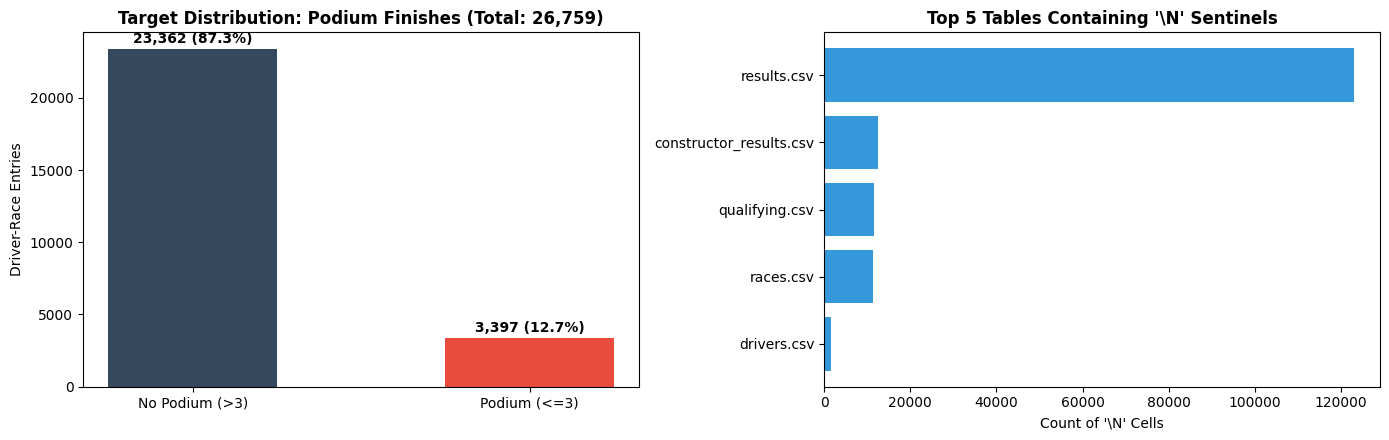

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

results_raw = dfs["results"].copy()
results_raw["target"] = (pd.to_numeric(results_raw["positionOrder"], errors="coerce") <= 3).map(
    {True: "Podium (<=3)", False: "No Podium (>3)"}
)
target_counts = results_raw["target"].value_counts()
axes[0].bar(target_counts.index, target_counts.values, color=["#34495e", "#e74c3c"], width=0.5)
axes[0].set_title(f"Target Distribution: Podium Finishes (Total: {len(results_raw):,})", fontweight="bold")
axes[0].set_ylabel("Driver-Race Entries")
for i, v in enumerate(target_counts.values):
    axes[0].text(i, v + 400, f"{v:,} ({v/len(results_raw):.1%})", ha="center", fontweight="bold")

top_sentinels = audit_df[audit_df[r"'\N' Sentinels"] > 0].head(5)
axes[1].barh(top_sentinels["Table"], top_sentinels[r"'\N' Sentinels"], color="#3498db")
axes[1].set_title(r"Top 5 Tables Containing '\N' Sentinels", fontweight="bold")
axes[1].set_xlabel(r"Count of '\N' Cells")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

### 1.2.1 Domain Verification: Grid == 0 (Pit-Lane Starts vs. DNQ)
As noted in the F1 rules companion, a grid position of `0` in modern regulations represents a **pit-lane start** (e.g., penalty or parc-ferme engine change). In historical eras (1970s–1990s), `grid == 0` also designated non-qualifiers (DNQ/DNPQ) who did not earn a slot on the physical starting grid.

In [8]:
grid_zero = results_raw[pd.to_numeric(results_raw["grid"], errors="coerce") == 0]
print(f"Total entries with grid == 0: {len(grid_zero):,}")
print("\nTop status reasons for grid == 0:")
print(grid_zero.merge(dfs["status"], on="statusId")["status"].value_counts().head(5))

Total entries with grid == 0: 1,638

Top status reasons for grid == 0:
status
Did not qualify       1013
Did not prequalify     331
Withdrew               164
+1 Lap                  27
Finished                22
Name: count, dtype: int64


### 1.2.2 Starting Grid Distribution & Podium Conversion Rate (P1 to P10)
We examine the starting grid distribution and measure how frequently starting in top grid positions converts into a podium finish. Pole position (P1) converts into a podium ~64% of the time, dropping sharply past P6.

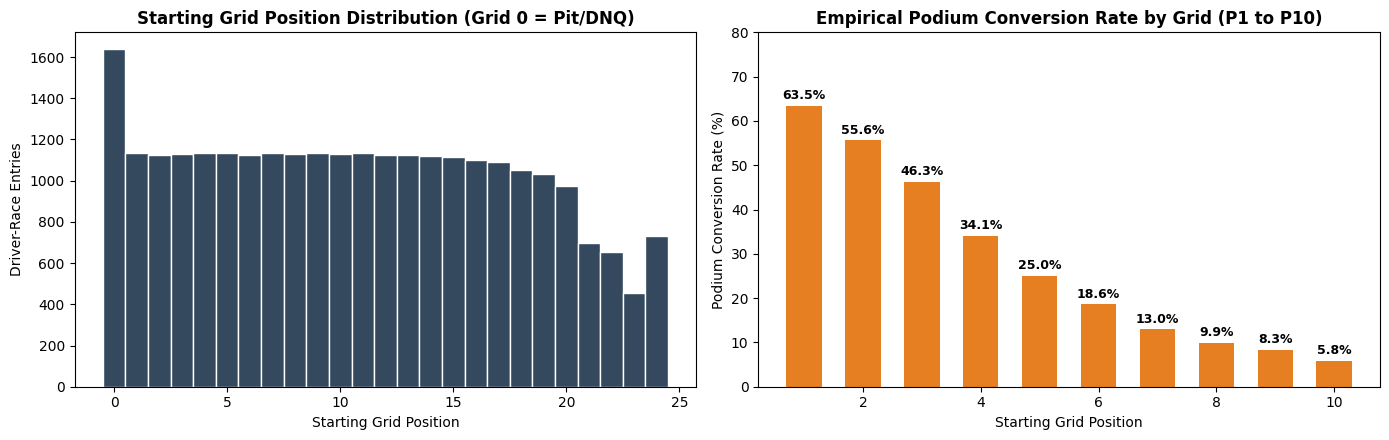

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
grid_num = pd.to_numeric(results_raw["grid"], errors="coerce")
pos_num = pd.to_numeric(results_raw["positionOrder"], errors="coerce")
podium_flag = (pos_num <= 3).astype(int)

axes[0].hist(grid_num.dropna(), bins=range(0, 26), color="#34495e", edgecolor="white", align="left")
axes[0].set_title("Starting Grid Position Distribution (Grid 0 = Pit/DNQ)", fontweight="bold")
axes[0].set_xlabel("Starting Grid Position")
axes[0].set_ylabel("Driver-Race Entries")

conv_df = pd.DataFrame({"grid": grid_num, "podium": podium_flag})
top10_conv = conv_df[conv_df["grid"].between(1, 10)].groupby("grid")["podium"].mean() * 100
axes[1].bar(top10_conv.index, top10_conv.values, color="#e67e22", width=0.6)
axes[1].set_title("Empirical Podium Conversion Rate by Grid (P1 to P10)", fontweight="bold")
axes[1].set_xlabel("Starting Grid Position")
axes[1].set_ylabel("Podium Conversion Rate (%)")
axes[1].set_ylim(0, 80)
for x, y in zip(top10_conv.index, top10_conv.values):
    axes[1].text(x, y + 1.5, f"{y:.1f}%", ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

### 1.2.3 Temporal Evolution: Calendar Expansion & Field Size Across Eras (1950–2024)
F1 evolved significantly: seasons grew from 7 races in 1950 to 24 in 2024. Meanwhile, field sizes shifted from oversubscribed 30+ car grids in the 1970s–1980s down to the strictly regulated 20-car grids of today.

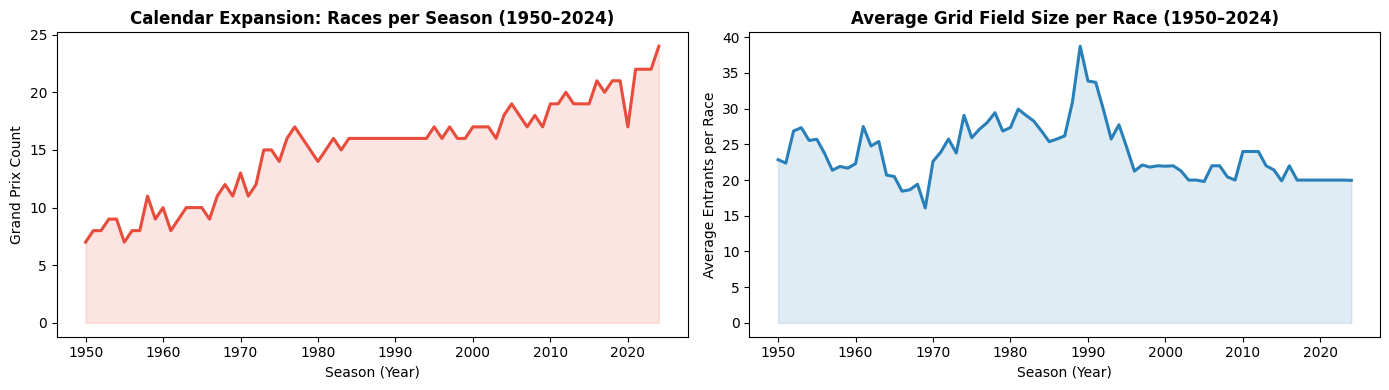

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
races_df = dfs["races"].copy()
races_df["year_num"] = pd.to_numeric(races_df["year"])
results_with_year = results_raw.merge(races_df[["raceId", "year_num"]], on="raceId")

races_per_year = races_df.groupby("year_num")["raceId"].count()
axes[0].plot(races_per_year.index, races_per_year.values, color="#e74c3c", lw=2.2)
axes[0].fill_between(races_per_year.index, races_per_year.values, color="#e74c3c", alpha=0.15)
axes[0].set_title("Calendar Expansion: Races per Season (1950–2024)", fontweight="bold")
axes[0].set_xlabel("Season (Year)")
axes[0].set_ylabel("Grand Prix Count")

field_size = results_with_year.groupby(["year_num", "raceId"]).size().groupby("year_num").mean()
axes[1].plot(field_size.index, field_size.values, color="#2980b9", lw=2.2)
axes[1].fill_between(field_size.index, field_size.values, color="#2980b9", alpha=0.15)
axes[1].set_title("Average Grid Field Size per Race (1950–2024)", fontweight="bold")
axes[1].set_xlabel("Season (Year)")
axes[1].set_ylabel("Average Entrants per Race")

plt.tight_layout()
plt.show()

### 1.3 Sentinel Replacement (`\N` $\rightarrow$ `np.nan`)
To preserve data integrity, raw tables remain immutable. We create a dictionary of working copies (`cleaned_dfs`) where all literal strings `\N` are replaced with `np.nan`.

In [11]:
cleaned_dfs = {}
for name, df in dfs.items():
    cleaned_dfs[name] = df.replace(r"\N", np.nan).copy()

total_sentinels_after = sum((df.astype(str) == r"\N").sum().sum() for df in cleaned_dfs.values())
print(f"Total sentinels remaining across all cleaned tables: {total_sentinels_after}")

Total sentinels remaining across all cleaned tables: 0


### 1.3.1 Impact of Cleaning: True Missingness Unmasked (Before vs. After)
Before sentinel cleaning, columns with literal `\N` strings reported 0% missingness under `.isna()`. Replacing sentinels unmasks the true missingness across post-race and telemetry fields.

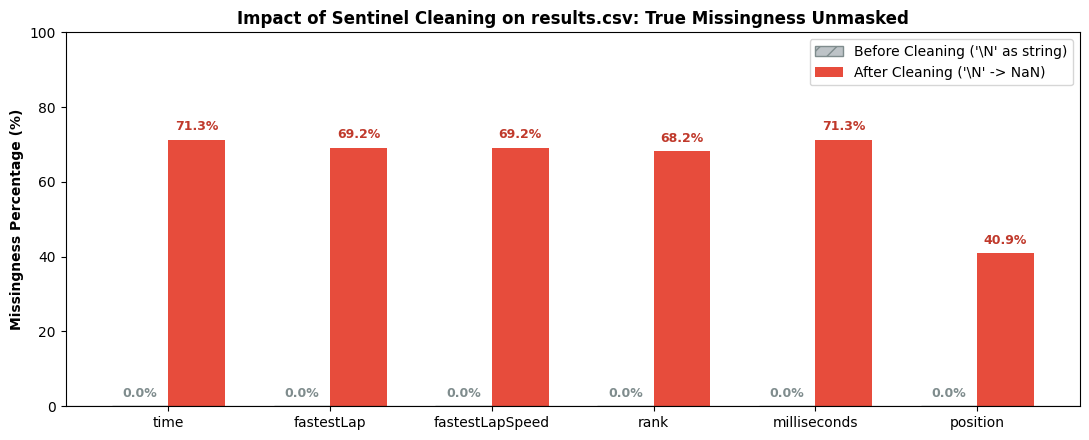

In [12]:
cols_to_compare = ["time", "fastestLap", "fastestLapSpeed", "rank", "milliseconds", "position"]
missing_before = (results_raw[cols_to_compare].isna().mean() * 100).round(1)
missing_after = (cleaned_dfs["results"][cols_to_compare].isna().mean() * 100).round(1)

fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(cols_to_compare))
width = 0.35

ax.bar(x - width/2, missing_before, width, label=r"Before Cleaning ('\N' as string)", color="#bdc3c7", edgecolor="#7f8c8d", hatch="//")
ax.bar(x + width/2, missing_after, width, label=r"After Cleaning ('\N' -> NaN)", color="#e74c3c")
ax.set_title("Impact of Sentinel Cleaning on results.csv: True Missingness Unmasked", fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(cols_to_compare)
ax.set_ylabel("Missingness Percentage (%)", fontweight="bold")
ax.set_ylim(0, 100)
ax.axhline(0, color="black", lw=0.8)
ax.legend(frameon=True, loc="upper right")

for i in range(len(cols_to_compare)):
    ax.text(x[i] - width/2, 2.5, f"{missing_before.iloc[i]:.1f}%", ha="center", fontsize=9, fontweight="bold", color="#7f8c8d")
    ax.text(x[i] + width/2, missing_after.iloc[i] + 2.5, f"{missing_after.iloc[i]:.1f}%", ha="center", fontsize=9, fontweight="bold", color="#c0392b")

plt.tight_layout()
plt.show()


### 1.4 Semantic Type Casting
We convert dates to `datetime64[ns]`, ordinals and positions to numeric types, and parse lap-time and pit-stop duration strings into numeric seconds.

In [13]:
def parse_lap_to_seconds(val):
    if pd.isna(val) or str(val).strip() == "":
        return np.nan
    try:
        val_str = str(val).strip()
        if ":" in val_str:
            parts = val_str.split(":")
            return float(parts[0]) * 60.0 + float(parts[1])
        return float(val_str)
    except Exception:
        return np.nan

cleaned_dfs["results"]["grid"] = pd.to_numeric(cleaned_dfs["results"]["grid"], errors="coerce")
cleaned_dfs["results"]["positionOrder"] = pd.to_numeric(cleaned_dfs["results"]["positionOrder"], errors="coerce")
cleaned_dfs["results"]["points"] = pd.to_numeric(cleaned_dfs["results"]["points"], errors="coerce").fillna(0.0)
cleaned_dfs["results"]["laps"] = pd.to_numeric(cleaned_dfs["results"]["laps"], errors="coerce")

cleaned_dfs["races"]["year"] = pd.to_numeric(cleaned_dfs["races"]["year"], errors="coerce")
cleaned_dfs["races"]["round"] = pd.to_numeric(cleaned_dfs["races"]["round"], errors="coerce")
cleaned_dfs["races"]["date"] = pd.to_datetime(cleaned_dfs["races"]["date"], errors="coerce")
cleaned_dfs["drivers"]["dob"] = pd.to_datetime(cleaned_dfs["drivers"]["dob"], errors="coerce")

cleaned_dfs["qualifying"]["position"] = pd.to_numeric(cleaned_dfs["qualifying"]["position"], errors="coerce")
for col in ["q1", "q2", "q3"]:
    cleaned_dfs["qualifying"][f"{col}_sec"] = cleaned_dfs["qualifying"][col].apply(parse_lap_to_seconds)
cleaned_dfs["pit_stops"]["duration_sec"] = pd.to_numeric(cleaned_dfs["pit_stops"]["duration"], errors="coerce")

print("Semantic type casting completed successfully.")

Semantic type casting completed successfully.


### 1.5 Relational Integrity: Primary Key Verification
Primary keys must uniquely identify each row in a table and cannot contain null values. We programmatically verify this across all relational tables.

In [14]:
pk_definitions = {
    "circuits": "circuitId",
    "constructors": "constructorId",
    "constructor_results": "constructorResultsId",
    "constructor_standings": "constructorStandingsId",
    "drivers": "driverId",
    "driver_standings": "driverStandingsId",
    "qualifying": "qualifyId",
    "races": "raceId",
    "results": "resultId",
    "seasons": "year",
    "status": "statusId"
}

pk_all_pass = True
for tbl, pk in pk_definitions.items():
    s = cleaned_dfs[tbl][pk]
    is_unique = s.is_unique
    no_nulls = not s.isna().any()
    status = "PASS" if (is_unique and no_nulls) else "FAIL"
    if not (is_unique and no_nulls):
        pk_all_pass = False
    print(f"[{status}] {tbl}.{pk} (Unique: {is_unique}, Nulls: {s.isna().sum()})")

assert pk_all_pass, "Primary key integrity check failed!"

[PASS] circuits.circuitId (Unique: True, Nulls: 0)
[PASS] constructors.constructorId (Unique: True, Nulls: 0)
[PASS] constructor_results.constructorResultsId (Unique: True, Nulls: 0)
[PASS] constructor_standings.constructorStandingsId (Unique: True, Nulls: 0)
[PASS] drivers.driverId (Unique: True, Nulls: 0)
[PASS] driver_standings.driverStandingsId (Unique: True, Nulls: 0)
[PASS] qualifying.qualifyId (Unique: True, Nulls: 0)
[PASS] races.raceId (Unique: True, Nulls: 0)
[PASS] results.resultId (Unique: True, Nulls: 0)
[PASS] seasons.year (Unique: True, Nulls: 0)
[PASS] status.statusId (Unique: True, Nulls: 0)


### 1.6 Relational Integrity: Foreign Key Reconciliation
Every foreign key value in a child table must exist in the referenced parent table. We reconcile all key relational joins to guarantee that no orphan records exist.

In [15]:
fk_definitions = [
    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),
    ("races", "circuitId", "circuits", "circuitId"),
    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),
    ("driver_standings", "raceId", "races", "raceId"),
    ("driver_standings", "driverId", "drivers", "driverId"),
    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId")
]

fk_all_pass = True
for child_tbl, child_fk, parent_tbl, parent_pk in fk_definitions:
    child_ids = cleaned_dfs[child_tbl][child_fk].dropna().unique()
    parent_ids = set(cleaned_dfs[parent_tbl][parent_pk].unique())
    orphans = set(child_ids) - parent_ids
    if len(orphans) == 0:
        print(f"[PASS] {child_tbl}.{child_fk} -> {parent_tbl}.{parent_pk}")
    else:
        print(f"[FAIL] {child_tbl}.{child_fk} -> {parent_tbl}.{parent_pk} ({len(orphans)} orphans)")
        fk_all_pass = False

assert fk_all_pass, "Foreign key reconciliation check failed!"

[PASS] results.raceId -> races.raceId
[PASS] results.driverId -> drivers.driverId
[PASS] results.constructorId -> constructors.constructorId
[PASS] results.statusId -> status.statusId
[PASS] races.circuitId -> circuits.circuitId
[PASS] qualifying.raceId -> races.raceId
[PASS] qualifying.driverId -> drivers.driverId
[PASS] qualifying.constructorId -> constructors.constructorId
[PASS] driver_standings.raceId -> races.raceId
[PASS] driver_standings.driverId -> drivers.driverId
[PASS] constructor_standings.raceId -> races.raceId
[PASS] constructor_standings.constructorId -> constructors.constructorId


### 1.7 Enforcing Modeling Grain: Shared Drives (1950s Anomaly)
Our prediction unit is **one driver entering one race**: `(raceId, driverId)` must be strictly unique.
* **The Anomaly**: `results.csv` contains 176 duplicate rows for `(raceId, driverId)`.
* **Domain Explanation**: In early F1 (primarily 1950–1957), regulations permitted **shared drives**. If a star driver's car retired, they could take over a teammate's car mid-race, producing multiple result rows for that driver in a single race.

In [16]:
res = cleaned_dfs["results"].copy()
dup_mask = res.duplicated(subset=["raceId", "driverId"], keep=False)

print(f"Total rows in raw results: {len(res):,}")
print(f"Rows involved in duplicate (raceId, driverId): {dup_mask.sum():,}")

dup_races = res[dup_mask].merge(cleaned_dfs["races"][["raceId", "year"]], on="raceId")
dup_decade_counts = (dup_races["year"] // 10 * 10).value_counts().sort_index().rename(lambda y: f"{y}s")
print("\nShared drive duplicates by decade:")
print(dup_decade_counts)

Total rows in raw results: 26,759
Rows involved in duplicate (raceId, driverId): 176

Shared drive duplicates by decade:
year
1950s    164
1960s     10
1970s      2
Name: count, dtype: int64


### 1.7.1 Visualization: Shared Drive Duplicates Across Eras
We visualize the chronological distribution of shared-drive duplicates. Over 93% (164 of 176) occurred in the 1950s, confirming they represent historical regulations rather than modern telemetry bugs.

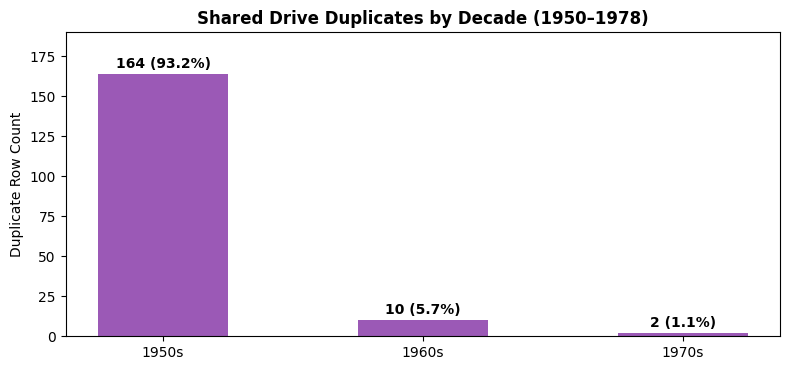

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(dup_decade_counts.index, dup_decade_counts.values, color="#9b59b6", width=0.5)
ax.set_title("Shared Drive Duplicates by Decade (1950–1978)", fontweight="bold")
ax.set_ylabel("Duplicate Row Count")
ax.set_ylim(0, 190)
for bar in bars:
    y = bar.get_height()
    pct = y / dup_decade_counts.sum() * 100
    ax.text(bar.get_x() + bar.get_width()/2, y + 4, f"{y} ({pct:.1f}%)", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

### 1.8 Deduplication Rule & Verification
**Rule Choice & Domain Justification**:
1. Priority 1: Retain the car the driver **started the race in** (`grid > 0`). Our model makes pre-race predictions based on grid positions before lights out.
2. Priority 2: If both records have grid positions (or neither), retain the car with the superior finishing position (lower `positionOrder`).

In [18]:
res["started_car"] = (res["grid"] > 0).astype(int)

results_dedup = res.sort_values(
    by=["raceId", "driverId", "started_car", "positionOrder"],
    ascending=[True, True, False, True]
).drop_duplicates(subset=["raceId", "driverId"], keep="first").drop(columns=["started_car"]).copy()

print(f"Cleaned unique modeling table rows: {len(results_dedup):,}")
assert not results_dedup.duplicated(subset=["raceId", "driverId"]).any(), "Grain violation detected!"
print("[PASS] Modeling grain verified: Exactly 1 row per (raceId, driverId).")

Cleaned unique modeling table rows: 26,668
[PASS] Modeling grain verified: Exactly 1 row per (raceId, driverId).


### 1.8.1 Historical Edge Cases: Indianapolis 500 & Non-Qualifiers (DNQ)
We audit two historical F1 domain anomalies noted in the project companion:
1. **The Indianapolis 500 (1950–1960)**: 11 races included in the World Championship calendar that were run under USAC oval rules by American drivers who rarely competed in European F1. We audit these 11 races.
2. **Non-Qualifiers (DNQ/DNPQ)**: In oversubscribed eras (1980s–1990s), drivers who failed to qualify never took the race start (`grid == 0`). We verify that exactly 0 of these 1,356 entries ever scored a podium finish.

In [32]:
indy_races = cleaned_dfs["races"][cleaned_dfs["races"]["name"].str.contains("Indianapolis 500", case=False, na=False)]
print(f"Total Indianapolis 500 races (1950–1960): {len(indy_races)}")

dnq_status_ids = cleaned_dfs["status"][cleaned_dfs["status"]["status"].str.contains("qualify", case=False, na=False)]["statusId"]
dnq_entries = results_dedup[results_dedup["statusId"].isin(dnq_status_ids)]
print(f"Total DNQ/DNPQ entries in results: {len(dnq_entries):,}")
print(f"Podium finishes among non-qualifiers (must be 0): {(dnq_entries['positionOrder'] <= 3).sum()}")


Total Indianapolis 500 races (1950–1960): 11
Total DNQ/DNPQ entries in results: 1,354
Podium finishes among non-qualifiers (must be 0): 0


### 1.9 Post-Cleaning EDA: Historical Qualifying Coverage Drift
The `qualifying.csv` table records detailed knockout times only from 1994 onwards (0% coverage before 1994). This empirical finding proves that our modeling pipeline must use `results.grid` as the primary pre-race starting position to avoid dropping historical races.

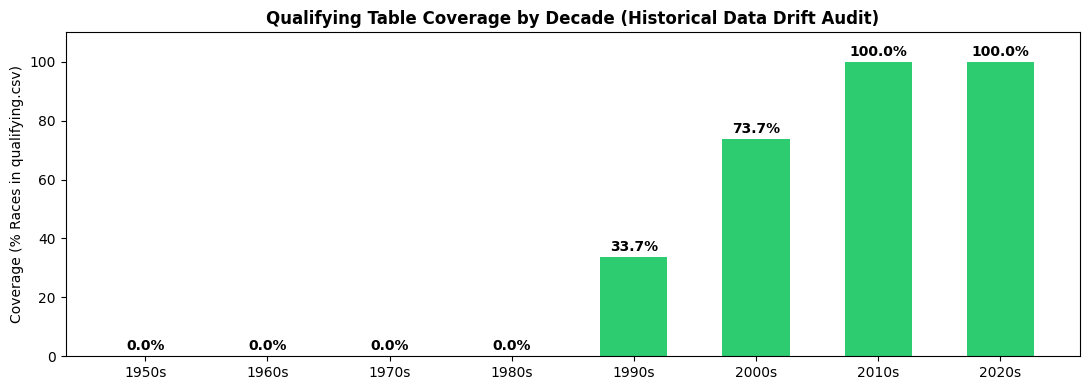

Audit Insight: qualifying.csv coverage is 0% before 1994.
Conclusion: Fallback to results.grid is mandatory for historical data integrity.


In [20]:
audit_races = results_dedup.merge(cleaned_dfs["races"][["raceId", "year"]], on="raceId")
qual_race_ids = set(cleaned_dfs["qualifying"]["raceId"].unique())
audit_races["has_qualifying"] = audit_races["raceId"].isin(qual_race_ids)

coverage = audit_races.groupby((audit_races["year"] // 10) * 10)["has_qualifying"].agg(["count", "mean"]).reset_index()
coverage["decade"] = coverage["year"].astype(str) + "s"

fig, ax = plt.subplots(figsize=(11, 4))
bars = ax.bar(coverage["decade"], coverage["mean"] * 100, color="#2ecc71", width=0.55)
ax.set_title("Qualifying Table Coverage by Decade (Historical Data Drift Audit)", fontweight="bold")
ax.set_ylabel("Coverage (% Races in qualifying.csv)")
ax.set_ylim(0, 110)
for bar in bars:
    y = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, y + 2, f"{y:.1f}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

print("Audit Insight: qualifying.csv coverage is 0% before 1994.")
print("Conclusion: Fallback to results.grid is mandatory for historical data integrity.")

---
# Member 2 — Required Data-Engineering Questions

> **Status: NOT STARTED. Add Member 2's analysis cells here before Member 3's feature-engineering section.**

1. **Q1:** Rank circuits by front-row-to-podium conversion, comparing pre-2014 with 2014 onward. Use actual `grid` for front-row starts and distinguish it from qualifying position.
2. **Q2:** Test home-race podium advantage while controlling for grid position. Document the driver-nationality to circuit-country mapping.
3. **Q3:** Compare constructor mechanical-retirement rates in 2014-2021 versus 2022-2024. Publish and justify the status mapping and denominator.

For each question, state the tables and join keys, analysis grain, missingness/exclusion policy, calculation, visualization, conclusion, and limitation.

---
# 2. Member 3 — Historical Feature Engineering

> **Member 3 status: MOSTLY COMPLETE**
>
> **Start here** for the target and leakage-safe historical feature table. The target, grid/qualifying inputs, historical driver/constructor form, and earlier-round standings are implemented below. Before sign-off, resolve the `TODO_MEMBER1`, `TODO_MEMBER2`, and duplicate-rule review after Member 2 provides EDA evidence.

**Original teammate cells above this heading are preserved without edits.** This section starts from the existing `results_dedup` and `cleaned_dfs` objects. It prepares exactly one target and one row per `(raceId, driverId)` using only information available after qualifying and before the race. All joins are validated.

**Code reminder tags:** `# TODO_MEMBER1` = confirm a cleaning or join decision; `# TODO_MEMBER2` = add EDA evidence; `# TEMPORARY` = provisional modeling assumption; `# REVIEW_INTEGRATION` = check when the full submission is assembled; `# LEAKAGE_CHECK` = guard against post-race information.

### 2.1 Check teammate outputs and build the driver–race base

Join race metadata onto the deduplicated results. The *target* comes from `positionOrder`, but `positionOrder` and every other current-race outcome are **never model inputs**. We preserve identifiers to make auditing and later joins straightforward.

In [21]:
from sklearn.model_selection import ParameterGrid

assert "cleaned_dfs" in globals() and "results_dedup" in globals(), (
    "Run the original Member 1 notebook cells first."
)

# TODO_MEMBER1: Confirm results_dedup is the agreed final one-row-per-driver-race table.
# REVIEW_INTEGRATION: Original duplicate selection uses positionOrder as a tie-break;
# decide as a team whether to replace that rule without changing original cells.
base = results_dedup.copy()
assert not base.duplicated(["raceId", "driverId"]).any()
assert base["positionOrder"].notna().all(), "Missing finishing order: target cannot be built safely."

race_metadata = cleaned_dfs["races"][["raceId", "year", "round", "date", "circuitId"]].copy()
assert race_metadata["raceId"].is_unique
base = base.merge(race_metadata, on="raceId", how="left", validate="many_to_one")
assert base[["year", "round", "date"]].notna().all().all(), "Missing race chronology after join."
base["year"] = pd.to_numeric(base["year"], errors="raise").astype(int)
base["round"] = pd.to_numeric(base["round"], errors="raise").astype(int)
base["date"] = pd.to_datetime(base["date"], errors="raise")
base["podium"] = (pd.to_numeric(base["positionOrder"], errors="raise") <= 3).astype(int)
base["grid"] = pd.to_numeric(base["grid"], errors="coerce")
base = base.sort_values(["year", "round", "date", "raceId", "driverId"]).reset_index(drop=True)
assert len(base) == len(results_dedup)
print("Base rows:", len(base), "| unique driver-race pairs:",
      base[["raceId", "driverId"]].drop_duplicates().shape[0])
print("Years:", base["year"].min(), "to", base["year"].max())
display(base[["raceId", "driverId", "constructorId", "year", "round", "grid", "podium"]].head())

Base rows: 26668 | unique driver-race pairs: 26668
Years: 1950 to 2024


,raceId,driverId,constructorId,year,round,grid,podium
0,833,579,51,1950,1,3,0
1,833,589,105,1950,1,11,0
2,833,619,151,1950,1,13,0
3,833,627,154,1950,1,9,0
4,833,640,105,1950,1,8,0


### 2.2 Qualifying features (known before the race)

Qualifying position can differ from the grid after penalties. Join qualifying using **both** driver and race IDs. Older seasons have incomplete qualifying data, so missing qualifying values remain missing for the later preprocessing stage. We also record whether qualifying data was available, rather than making up historical times.

In [22]:
qual = cleaned_dfs["qualifying"].copy()
qual_cols = [c for c in ["raceId", "driverId", "position", "q1_sec", "q2_sec", "q3_sec"] if c in qual.columns]
qual = qual[qual_cols].copy()
qual["qualifying_position"] = pd.to_numeric(qual["position"], errors="coerce")
qual = qual.drop(columns=["position"])

# TODO_MEMBER1: Verify unexpected duplicate qualifying keys; choose an auditable rule if present.
q_dup = int(qual.duplicated(["raceId", "driverId"]).sum())
print("Duplicated qualifying driver-race keys:", q_dup)
if q_dup:
    # TEMPORARY: Keep earliest source row; do not silently multiply model rows.
    qual = qual.drop_duplicates(["raceId", "driverId"], keep="first")

feature_df = base.merge(qual, on=["raceId", "driverId"], how="left", validate="one_to_one")
feature_df["qualifying_available"] = feature_df["qualifying_position"].notna().astype(int)
feature_df["grid_top3"] = feature_df["grid"].between(1, 3).astype(int)
feature_df["grid_top5"] = feature_df["grid"].between(1, 5).astype(int)

# LEAKAGE_CHECK: These qualifying and grid columns are pre-race; race finishing data is not.
assert len(feature_df) == len(base)
print("Qualifying-position availability: {:.1%}".format(feature_df["qualifying_available"].mean()))

Duplicated qualifying driver-race keys: 0
Qualifying-position availability: 39.4%


### 2.3 Driver historical form using completed earlier races

We calculate past podium rates from previously completed races. `shift(1)` excludes the current row. For a driver with no history, the historical rate is left as missing; Member 4 will impute it using training-only statistics.

In [23]:
feature_df = feature_df.sort_values(["year", "round", "date", "raceId", "driverId"]).copy()

# LEAKAGE_CHECK: Driver form calculations exclude the current race using shift(1).
driver_grp = feature_df.groupby("driverId", sort=False)
feature_df["driver_races_before"] = driver_grp.cumcount()
feature_df["driver_podium_rate_before"] = driver_grp["podium"].transform(
    lambda s: s.shift(1).expanding(min_periods=1).mean()
)
feature_df["driver_last5_podium_rate"] = driver_grp["podium"].transform(
    lambda s: s.shift(1).rolling(5, min_periods=1).mean()
)

# TODO_MEMBER2: Add EDA plots/hypotheses supporting these historical windows.
# TEMPORARY: A five-race window is a reasonable starting hypothesis, not a tuned optimum.
print(feature_df[["driverId", "year", "round", "driver_races_before",
                  "driver_last5_podium_rate"]].head(8).to_string(index=False))
assert feature_df.loc[feature_df["driver_races_before"].eq(0),
                      "driver_last5_podium_rate"].isna().all()

 driverId  year  round  driver_races_before  driver_last5_podium_rate
      579  1950      1                    0                       NaN
      589  1950      1                    0                       NaN
      619  1950      1                    0                       NaN
      627  1950      1                    0                       NaN
      640  1950      1                    0                       NaN
      642  1950      1                    0                       NaN
      660  1950      1                    0                       NaN
      661  1950      1                    0                       NaN


### 2.4 Constructor form without same-race teammate leakage

A team normally enters more than one driver in a race. We **first aggregate at constructor–race level**, then shift and roll over completed previous races. This prevents a teammate's result from the *same race* appearing as a pre-race feature.

In [24]:
team_race = (feature_df.groupby(["constructorId", "raceId", "year", "round", "date"], as_index=False)
             .agg(team_podiums=("podium", "sum"), team_entries=("driverId", "nunique")))
team_race["team_podium_fraction"] = team_race["team_podiums"] / team_race["team_entries"]
team_race = team_race.sort_values(["year", "round", "date", "raceId", "constructorId"])
team_grp = team_race.groupby("constructorId", sort=False)
team_race["constructor_races_before"] = team_grp.cumcount()
team_race["constructor_last5_podium_rate"] = team_grp["team_podium_fraction"].transform(
    lambda s: s.shift(1).rolling(5, min_periods=1).mean()
)
team_race["constructor_podium_rate_before"] = team_grp["team_podium_fraction"].transform(
    lambda s: s.shift(1).expanding(min_periods=1).mean()
)
team_features = ["raceId", "constructorId", "constructor_races_before",
                 "constructor_last5_podium_rate", "constructor_podium_rate_before"]
feature_df = feature_df.merge(team_race[team_features],
                              on=["raceId", "constructorId"], how="left", validate="many_to_one")
# LEAKAGE_CHECK: Each teammate in the same constructor/race must get identical historical team form.
assert (feature_df.groupby(["raceId", "constructorId"])["constructor_last5_podium_rate"]
        .nunique(dropna=False) <= 1).all()
print("Constructor historical form created for", team_race["constructorId"].nunique(), "teams")

Constructor historical form created for 210 teams


### 2.5 Driver and constructor standings *before* the current race

The standings CSVs contain **post-race** points and positions. We attach the latest earlier standings within the same season, using a backward as-of join with `allow_exact_matches=False`. This also handles drivers who skip races more reliably than a simple group shift on sparse standings rows. First-round known points default to zero; missing previous rank remains missing.

In [25]:
def attach_prior_standings(frame, table, entity_key, prefix):
    """Attach the last known post-race standings from an earlier round of the same season."""
    standings = cleaned_dfs[table][["raceId", entity_key, "points", "position"]].copy()
    standings = standings.merge(
        race_metadata[["raceId", "year", "round"]], on="raceId", how="left", validate="many_to_one"
    )
    standings["points"] = pd.to_numeric(standings["points"], errors="coerce")
    standings["position"] = pd.to_numeric(standings["position"], errors="coerce")
    standings["year"] = pd.to_numeric(standings["year"], errors="coerce")
    standings["round"] = pd.to_numeric(standings["round"], errors="coerce")
    standings = standings.dropna(subset=[entity_key, "year", "round"])

    # TODO_MEMBER1: Confirm there are no duplicate standings entries per entity/race.
    duplicates = int(standings.duplicated(["raceId", entity_key]).sum())
    print(f"{prefix} standings duplicate keys: {duplicates}")
    if duplicates:
        # TEMPORARY: Keep last entry; review if raw data contains unusual historical duplication.
        standings = standings.drop_duplicates(["raceId", entity_key], keep="last")

    left = frame[["raceId", entity_key, "year", "round"]].copy()
    left["__original_order"] = np.arange(len(left))
    left["__entity_year"] = left[entity_key].astype(str) + ":" + left["year"].astype(int).astype(str)
    standings["__entity_year"] = standings[entity_key].astype(str) + ":" + standings["year"].astype(int).astype(str)

    # LEAKAGE_CHECK: backward join excludes the *same* round and all future rounds.
    left_sorted = left.sort_values("round")
    right_sorted = standings[["__entity_year", "round", "points", "position"]].sort_values("round")
    joined = pd.merge_asof(
        left_sorted, right_sorted, on="round", by="__entity_year",
        direction="backward", allow_exact_matches=False
    ).sort_values("__original_order")
    assert np.array_equal(joined["__original_order"].to_numpy(), np.arange(len(frame)))
    assert len(joined) == len(frame)
    return (joined["points"].fillna(0).to_numpy(dtype=float),
            joined["position"].to_numpy(dtype=float))

feature_df["driver_points_before_race"], feature_df["driver_rank_before_race"] = (
    attach_prior_standings(feature_df, "driver_standings", "driverId", "driver")
)
feature_df["constructor_points_before_race"], feature_df["constructor_rank_before_race"] = (
    attach_prior_standings(feature_df, "constructor_standings", "constructorId", "constructor")
)
print("Pre-race standings attached. Example:")
display(feature_df[["year", "round", "driverId", "driver_points_before_race",
                    "constructor_points_before_race"]].tail(8))

driver standings duplicate keys: 0
constructor standings duplicate keys: 0
Pre-race standings attached. Example:


,year,round,driverId,driver_points_before_race,constructor_points_before_race
26660,2024,24,847,235.0,446.0
26661,2024,24,848,12.0,17.0
26662,2024,24,852,30.0,46.0
26663,2024,24,855,4.0,4.0
26664,2024,24,857,291.0,640.0
26665,2024,24,859,4.0,46.0
26666,2024,24,861,5.0,17.0
26667,2024,24,862,0.0,59.0


### 2.6 Historical feature validation and candidate feature catalogue

We check the modeling grain and inspect missingness without changing Member 1's cleaning decisions. The final choice of predictors must still be supported by Member 2's EDA.

In [26]:
# TEMPORARY: Candidate features; Member 2's evidence may change these.
numeric_features = [
    "grid", "grid_top3", "grid_top5", "qualifying_position", "qualifying_available",
    "driver_races_before", "driver_podium_rate_before", "driver_last5_podium_rate",
    "constructor_races_before", "constructor_last5_podium_rate",
    "constructor_podium_rate_before", "driver_points_before_race",
    "driver_rank_before_race", "constructor_points_before_race",
    "constructor_rank_before_race"
]
# TEMPORARY: Add circuit and constructor identifiers as categorical labels (not magnitude values).
categorical_features = ["circuitId", "constructorId"]
selected_features = numeric_features + categorical_features

# LEAKAGE_CHECK: Explicitly exclude current result fields from features.
for forbidden in ["podium", "positionOrder", "points", "statusId", "laps", "milliseconds",
                  "fastestLap", "fastestLapTime", "fastestLapSpeed", "resultId"]:
    assert forbidden not in selected_features, f"Forbidden input: {forbidden}"
assert feature_df[["raceId", "driverId"]].notna().all().all()
assert not feature_df.duplicated(["raceId", "driverId"]).any()
assert len(feature_df) == len(results_dedup)
assert feature_df["podium"].isin([0, 1]).all()
assert set(selected_features).issubset(feature_df.columns)
print("Validated rows:", len(feature_df), "| Candidate inputs:", len(selected_features))
display((feature_df[selected_features].isna().mean() * 100)
        .sort_values(ascending=False).head(12).rename("Missing percentage").to_frame())

# REVIEW_INTEGRATION: Compare selected features against completed Member 2 plots and conclusions.

Validated rows: 26668 | Candidate inputs: 17


,Missing percentage
qualifying_position,60.649468
driver_rank_before_race,13.728064
constructor_rank_before_race,13.218089
driver_last5_podium_rate,3.228589
driver_podium_rate_before,3.228589
constructor_last5_podium_rate,1.297435
constructor_podium_rate_before,1.297435
grid,0.000000
grid_top3,0.000000
constructor_races_before,0.000000


---
# 3. Member 4 — Feature Selection, Temporal Splits, and Preprocessing

> **Member 4 status: MOSTLY COMPLETE**
>
> **Start here** for candidate-feature selection, chronological splitting, and preprocessing. Train-only imputation/encoding/scaling, distribution checks, and two preprocessing-order experiments are implemented below. Finalize the feature list and rationale after Member 2 completes the required EDA.

All feature decisions remain provisional until supported by Member 2's finished EDA. This section builds reproducible training/validation/test data, with preprocessing learned **only from training**.

### 3.1 Chronological split

Train on seasons through **2019**, validate on **2020–2021**, and reserve **2022–2024** for the untouched final test set. These boundaries follow the project's F1 companion as a reasonable starting split and must be justified in the report. No random splitting is used.

In [27]:
# TEMPORARY: Confirm year boundaries when Member 2 finishes era/coverage EDA.
train_df = feature_df.loc[feature_df["year"] <= 2019].copy()
val_df = feature_df.loc[feature_df["year"].between(2020, 2021)].copy()
test_df = feature_df.loc[feature_df["year"] >= 2022].copy()
assert all(len(d) > 0 for d in [train_df, val_df, test_df]), "One temporal split is empty. Check data coverage."
assert set(train_df["raceId"]).isdisjoint(set(val_df["raceId"]))
assert set(val_df["raceId"]).isdisjoint(set(test_df["raceId"]))
assert set(train_df["raceId"]).isdisjoint(set(test_df["raceId"]))

X_train, y_train = train_df[selected_features].copy(), train_df["podium"].astype(int).copy()
X_val, y_val = val_df[selected_features].copy(), val_df["podium"].astype(int).copy()
X_test, y_test = test_df[selected_features].copy(), test_df["podium"].astype(int).copy()

split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Rows": [len(train_df), len(val_df), len(test_df)],
    "Min year": [x["year"].min() for x in [train_df, val_df, test_df]],
    "Max year": [x["year"].max() for x in [train_df, val_df, test_df]],
    "Podium rate": [y_train.mean(), y_val.mean(), y_test.mean()]
})
display(split_summary)

,Split,Rows,Min year,Max year,Podium rate
0,Train,24529,1950,2019,0.125321
1,Validation,780,2020,2021,0.150000
2,Test,1359,2022,2024,0.150110


### 3.2 Fit an sklearn preprocessing pipeline on training only

Numerical fields: median imputation + standard scaling. Categorical IDs: most-frequent imputation + one-hot encoding that tolerates unseen categories. Missing prior history is handled by the learned imputer rather than pretending first-time drivers have known performance. Tree models can later reuse unscaled features via a separate pipeline if justified.

In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# TODO_MEMBER2: Confirm whether adding circuit/team categories improves validation results.
# LEAKAGE_CHECK: .fit_transform is applied only to training observations.
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", num_pipeline, numeric_features),
    ("cat", cat_pipeline, categorical_features)
], remainder="drop", sparse_threshold=0.3)

Xtr_sc = preprocessor.fit_transform(X_train)
Xva_sc = preprocessor.transform(X_val)
Xte_sc = preprocessor.transform(X_test)
model_feature_names = preprocessor.get_feature_names_out()
assert Xtr_sc.shape[1] == Xva_sc.shape[1] == Xte_sc.shape[1]
assert np.isfinite(Xtr_sc.data if hasattr(Xtr_sc, "toarray") else Xtr_sc).all()
assert np.isfinite(Xva_sc.data if hasattr(Xva_sc, "toarray") else Xva_sc).all()
assert np.isfinite(Xte_sc.data if hasattr(Xte_sc, "toarray") else Xte_sc).all()
print("Model-ready matrices:", Xtr_sc.shape, Xva_sc.shape, Xte_sc.shape)
print("First 12 processed features:", list(model_feature_names[:12]))

Model-ready matrices: (24529, 293) (780, 293) (1359, 293)
First 12 processed features: ['num__grid', 'num__grid_top3', 'num__grid_top5', 'num__qualifying_position', 'num__qualifying_available', 'num__driver_races_before', 'num__driver_podium_rate_before', 'num__driver_last5_podium_rate', 'num__constructor_races_before', 'num__constructor_last5_podium_rate', 'num__constructor_podium_rate_before', 'num__driver_points_before_race']


### 3.3 Evidence: How preprocessing changed the data

Compare missingness and the range of a selected numerical feature before vs after processing. This visualizes the effect of an actual step, as required in the milestone.

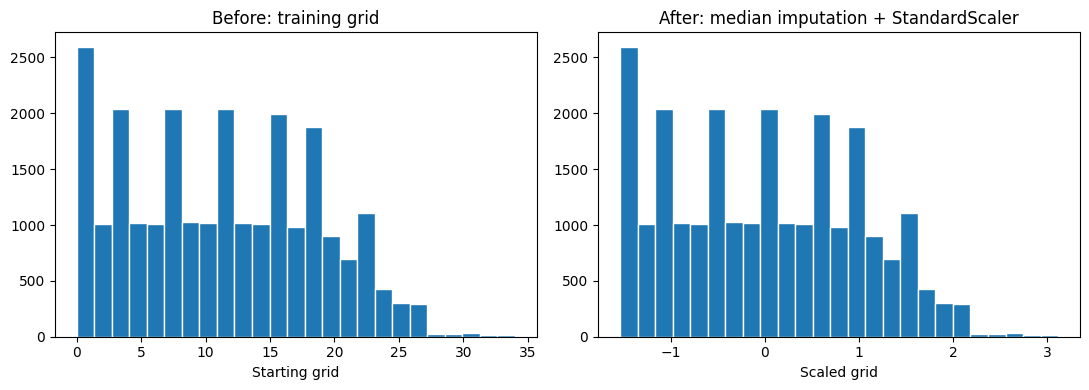

Grid missing before: 0 | Missing after: 0
Scaled train mean / std: 0.0 1.0


In [29]:
from scipy import sparse

chosen = "grid"
raw_grid = pd.to_numeric(X_train[chosen], errors="coerce")
processed_grid = Xtr_sc[:, numeric_features.index(chosen)]
if sparse.issparse(processed_grid):
    processed_grid = processed_grid.toarray()
processed_grid = np.asarray(processed_grid).ravel()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(raw_grid.dropna(), bins=25, edgecolor="white")
axes[0].set_title("Before: training grid")
axes[0].set_xlabel("Starting grid")
axes[1].hist(processed_grid, bins=25, edgecolor="white")
axes[1].set_title("After: median imputation + StandardScaler")
axes[1].set_xlabel("Scaled grid")
plt.tight_layout()
plt.show()
print("Grid missing before:", int(raw_grid.isna().sum()),
      "| Missing after:", int(pd.isna(processed_grid).sum()))
print("Scaled train mean / std:", round(processed_grid.mean(), 4), round(processed_grid.std(), 4))

### 3.4 Two controlled preprocessing-order experiments (validation only)

The milestone asks for at least two **order** experiments. We evaluate these without ever looking at test performance:

1. **Clipping vs mean imputation:** clip outliers *then* mean-impute, versus mean-impute *then* clip.
2. **Log transform vs mean imputation:** log-transform points *then* mean-impute, versus mean-impute *then* log-transform.

To isolate order, both approaches in each experiment use the same train/validation rows, a common numerical feature set, standard scaling, and logistic regression. These experiments are informative diagnostics, **not** a claim that the variations improve the eventual neural network. Some data distributions can yield tied results; ties are still reportable.

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

experiment_cols = ["grid", "qualifying_position", "driver_last5_podium_rate",
                   "constructor_last5_podium_rate", "driver_points_before_race",
                   "constructor_points_before_race"]
exp_train = X_train[experiment_cols].apply(pd.to_numeric, errors="coerce")
exp_val = X_val[experiment_cols].apply(pd.to_numeric, errors="coerce")

# LEAKAGE_CHECK: All learned cutoffs, means and scalers come solely from exp_train.
def prepare_experiment(train_x, val_x, method):
    a = train_x.copy().astype(float)
    b = val_x.copy().astype(float)
    if method in ("clip_then_impute", "impute_then_clip"):
        low, high = a.quantile(.01), a.quantile(.99)
        mean = a.mean()
        if method == "clip_then_impute":
            a, b = a.clip(lower=low, upper=high, axis=1), b.clip(lower=low, upper=high, axis=1)
            fill = a.mean()
            a, b = a.fillna(fill), b.fillna(fill)
        else:
            a, b = a.fillna(mean), b.fillna(mean)
            a, b = a.clip(lower=low, upper=high, axis=1), b.clip(lower=low, upper=high, axis=1)
    elif method in ("log_then_impute", "impute_then_log"):
        # Count/points features are nonnegative. log1p is monotonic but mean() is nonlinear under it.
        point_cols = ["driver_points_before_race", "constructor_points_before_race"]
        assert (a[point_cols].dropna() >= 0).all().all()
        assert (b[point_cols].dropna() >= 0).all().all()
        if method == "log_then_impute":
            a[point_cols], b[point_cols] = np.log1p(a[point_cols]), np.log1p(b[point_cols])
            fill = a.mean()
            a, b = a.fillna(fill), b.fillna(fill)
        else:
            fill = a.mean()
            a, b = a.fillna(fill), b.fillna(fill)
            a[point_cols], b[point_cols] = np.log1p(a[point_cols]), np.log1p(b[point_cols])
    else:
        raise ValueError("Unknown experimental pipeline")
    # Protect against an all-missing training column if the dataset/version changes.
    assert a.notna().all().all() and b.notna().all().all(), "Experiment has all-missing columns."
    scaler = StandardScaler()
    return scaler.fit_transform(a), scaler.transform(b)

experiment_records = []
for experiment_name, methods in [
    ("1 · outlier/mean-imputation order", ["clip_then_impute", "impute_then_clip"]),
    ("2 · log/mean-imputation order", ["log_then_impute", "impute_then_log"])
]:
    for method in methods:
        xt, xv = prepare_experiment(exp_train, exp_val, method)
        baseline = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
        baseline.fit(xt, y_train)
        val_proba = baseline.predict_proba(xv)[:, 1]
        experiment_records.append({
            "Experiment": experiment_name,
            "Preprocessing order": method,
            "Validation PR-AUC": average_precision_score(y_val, val_proba),
            "Validation ROC-AUC": roc_auc_score(y_val, val_proba),
        })
experiment_results = pd.DataFrame(experiment_records)
display(experiment_results.round(4))

# TODO_MEMBER2: Add a short interpretation linked to observed missingness/outlier EDA.
# REVIEW_INTEGRATION: Re-run experiments if final features or season boundaries change.
# LEAKAGE_CHECK: Test set was not used in these comparisons.

,Experiment,Preprocessing order,Validation PR-AUC,Validation ROC-AUC
0,1 · outlier/mean-imputation order,clip_then_impute,0.6709,0.9124
1,1 · outlier/mean-imputation order,impute_then_clip,0.6709,0.9124
2,2 · log/mean-imputation order,log_then_impute,0.6631,0.9147
3,2 · log/mean-imputation order,impute_then_log,0.6631,0.9147


### 3.5 Final contract, reproducibility checks, and hand-off to modeling

The next modeling section can consume `Xtr_sc`, `Xva_sc`, `Xte_sc`, `y_train`, `y_val`, `y_test`, `preprocessor`, `selected_features`, and `model_feature_names`. **Modeling, ablation and XAI have not been implemented here** because this deliverable covers Members 3 and 4 only. The final milestone still requires those stages, an inference demonstration, and Member 2's analytical answers.

In [31]:
assert len(X_train) == len(y_train) == Xtr_sc.shape[0]
assert len(X_val) == len(y_val) == Xva_sc.shape[0]
assert len(X_test) == len(y_test) == Xte_sc.shape[0]
assert set(y_train.unique()).issubset({0, 1})
assert set(y_val.unique()).issubset({0, 1})
assert set(y_test.unique()).issubset({0, 1})
assert not feature_df.duplicated(["raceId", "driverId"]).any()
assert not set(selected_features).intersection({"podium", "positionOrder", "points", "laps", "statusId"})
print("[PASS] Members 3 & 4 feature engineering / preprocessing checks")
print("[PASS] Train-only preprocessing; separate validation and unseen test")
print("[PASS] Two preprocessing-order experiments on validation only")
print("[REVIEW_INTEGRATION] Confirm teammate joins, EDA evidence, feature list, and duplicate rule")
print("Next: two statistical models + shallow NN, ablation, XAI, inference, report")

[PASS] Members 3 & 4 feature engineering / preprocessing checks
[PASS] Train-only preprocessing; separate validation and unseen test
[PASS] Two preprocessing-order experiments on validation only
[REVIEW_INTEGRATION] Confirm teammate joins, EDA evidence, feature list, and duplicate rule
Next: two statistical models + shallow NN, ablation, XAI, inference, report
